In [1]:
from google.colab import files

uploaded = files.upload()

Saving preprocessed_framingham.csv to preprocessed_framingham.csv
Saving preprocessed_heart_disease.csv to preprocessed_heart_disease.csv


# Mod_C
## Week 2

### Project: Cardiovascular Disease

This notebook continues the cardiovascular disease project developed in Module B.

Week 2 applies regularized linear regression techniques to the Statlog Heart Disease and
Framingham Heart Study datasets. The models examined are:

- Lasso Regression
- Ridge Regression
- Elastic Net Regression

These approaches add penalties to ordinary linear regression in order to reduce overly large
coefficients and help control model complexity.

The analysis will compare regularized models with a standard linear regression baseline using
training and testing performance, RMSE, cross-validation, and hyperparameter tuning.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

from sklearn.metrics import r2_score, mean_squared_error

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:
heart = pd.read_csv("/content/preprocessed_heart_disease.csv")
framingham = pd.read_csv("/content/preprocessed_framingham.csv")

print("Heart Disease dataset shape:", heart.shape)
print("Framingham dataset shape:", framingham.shape)

Heart Disease dataset shape: (270, 14)
Framingham dataset shape: (4238, 16)


## Regularization

Ordinary linear regression attempts to find coefficients that minimize prediction error.

Regularized regression adds an additional penalty for large coefficients. This can reduce model
complexity and help prevent overfitting.

### Lasso Regression
Lasso can shrink some coefficients completely to zero. Therefore, it can also act as a form of
feature selection.

### Ridge Regression
Ridge shrinks coefficients toward zero but generally keeps all predictors in the model.

### Elastic Net Regression
Elastic Net combines characteristics of both Lasso and Ridge.

The strength of regularization is controlled by a penalty parameter. The course refers to this
concept as lambda. In scikit-learn, the corresponding penalty-strength parameter is called `alpha`.

For Elastic Net, scikit-learn also uses `l1_ratio` to control the balance between Lasso-style and
Ridge-style regularization.

## Dataset 1: Statlog Heart Disease

The Statlog analysis will continue using maximum heart rate (`thalach`) as the continuous outcome.

The predictors are:

- age
- sex
- resting blood pressure (`trestbps`)
- cholesterol (`chol`)
- fasting blood sugar indicator (`fbs`)
- exercise-induced angina (`exang`)
- ST depression (`oldpeak`)

Some multi-category variables such as chest pain type and thalassemia are not included here because
their numerical codes represent categories rather than true continuous quantities and would require
additional categorical encoding.

The goal is to determine whether regularization improves prediction of maximum heart rate and
whether Lasso identifies any predictors that contribute little to the model.

## Dataset 2: Framingham Heart Study

The Framingham analysis will continue using systolic blood pressure (`sysBP`) as the continuous
outcome.

The predictors are:

- male
- age
- currentSmoker
- cigsPerDay
- BPMeds
- prevalentStroke
- diabetes
- total cholesterol (`totChol`)
- BMI
- heartRate
- glucose

Diastolic blood pressure and the prevalent hypertension indicator are excluded because they are
already very closely related to blood-pressure status and could dominate the prediction of systolic
blood pressure.

The goal is to compare standard linear regression with Lasso, Ridge, and Elastic Net and determine
whether regularization improves generalization.

## Feature Scaling

Before applying regularization, the predictors will be standardized.

Standardization places features on comparable scales so that the regularization penalty does not
unfairly penalize a variable simply because its numerical values are larger than those of another
variable.

In [4]:
def compare_regularized_models(df, predictors, target, dataset_name):

    # Keep the variables needed for this model
    data = df[predictors + [target]].dropna()

    X = data[predictors]
    y = data[target]

    # 80% training data, 20% testing data
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

    results = []

    # --------------------------------------------------
    # Ordinary Linear Regression baseline
    # --------------------------------------------------

    baseline = Pipeline([
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ])

    baseline.fit(X_train, y_train)

    train_predictions = baseline.predict(X_train)
    test_predictions = baseline.predict(X_test)

    baseline_cv_rmse = -cross_val_score(
        baseline,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error"
    ).mean()

    results.append({
        "Model": "Linear Regression",
        "Best alpha (lambda)": np.nan,
        "Best l1_ratio": np.nan,
        "Training R²": r2_score(y_train, train_predictions),
        "Testing R²": r2_score(y_test, test_predictions),
        "Testing RMSE": np.sqrt(
            mean_squared_error(y_test, test_predictions)
        ),
        "5-Fold CV RMSE": baseline_cv_rmse
    })

    # Lambda/alpha values to test
    alpha_values = np.logspace(-3, 2, 6)

    # --------------------------------------------------
    # Regularized models
    # --------------------------------------------------

    model_settings = {

        "Lasso": (
            Lasso(max_iter=50000),
            {
                "model__alpha": alpha_values
            }
        ),

        "Ridge": (
            Ridge(),
            {
                "model__alpha": alpha_values
            }
        ),

        "Elastic Net": (
            ElasticNet(max_iter=50000),
            {
                "model__alpha": alpha_values,
                "model__l1_ratio": [0.1, 0.5, 0.9]
            }
        )
    }

    searches = {}

    for model_name, (model, parameters) in model_settings.items():

        pipeline = Pipeline([
            ("scale", StandardScaler()),
            ("model", model)
        ])

        search = GridSearchCV(
            pipeline,
            param_grid=parameters,
            cv=5,
            scoring="neg_root_mean_squared_error"
        )

        search.fit(X_train, y_train)

        searches[model_name] = search

        train_predictions = search.predict(X_train)
        test_predictions = search.predict(X_test)

        results.append({
            "Model": model_name,
            "Best alpha (lambda)": search.best_params_["model__alpha"],
            "Best l1_ratio": search.best_params_.get(
                "model__l1_ratio",
                np.nan
            ),
            "Training R²": r2_score(
                y_train,
                train_predictions
            ),
            "Testing R²": r2_score(
                y_test,
                test_predictions
            ),
            "Testing RMSE": np.sqrt(
                mean_squared_error(
                    y_test,
                    test_predictions
                )
            ),
            "5-Fold CV RMSE": -search.best_score_
        })

    results_df = pd.DataFrame(results).round(3)

    print(dataset_name)
    display(results_df)

    return results_df, searches

### Statlog Regularization Model Comparison

A standard linear regression model will be compared with Lasso, Ridge, and Elastic Net.

Five-fold cross-validation is used to select the regularization strength that produces the lowest
cross-validation RMSE.

In [5]:
heart_predictors = [
    "age",
    "sex",
    "trestbps",
    "chol",
    "fbs",
    "exang",
    "oldpeak"
]

heart_results, heart_searches = compare_regularized_models(
    df=heart,
    predictors=heart_predictors,
    target="thalach",
    dataset_name="Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset


,Model,Best alpha (lambda),Best l1_ratio,Training R²,Testing R²,Testing RMSE,5-Fold CV RMSE
0,Linear Regression,NaN,NaN,0.365,0.198,21.616,18.809
1,Lasso,1.0,NaN,0.352,0.170,21.985,18.777
2,Ridge,10.0,NaN,0.365,0.197,21.621,18.770
3,Elastic Net,0.1,0.1,0.363,0.196,21.638,18.760


### Statlog Results Interpretation

Regularization did not substantially improve prediction performance for the Statlog dataset.

The ordinary linear regression model achieved a testing R² of 0.198 and a testing RMSE of 21.616.
Ridge regression produced almost identical performance with a testing R² of 0.197 and RMSE of
21.621.

Elastic Net also performed similarly, while Lasso reduced testing R² to 0.170 and increased RMSE
to 21.985.

Although the regularized models produced slightly lower cross-validation RMSE values, the differences
were extremely small. Elastic Net had the lowest cross-validation RMSE at 18.760, compared with
18.809 for ordinary linear regression.

Overall, the results suggest that strong regularization is not particularly beneficial for this Statlog
model. The ordinary linear model remains competitive and provides slightly better performance on the
held-out test set.

### Framingham Regularization Model Comparison

The same model comparison will be performed for systolic blood pressure in the Framingham dataset.

Five-fold cross-validation is again used to determine appropriate regularization strength.

In [6]:
framingham_predictors = [
    "male",
    "age",
    "currentSmoker",
    "cigsPerDay",
    "BPMeds",
    "prevalentStroke",
    "diabetes",
    "totChol",
    "BMI",
    "heartRate",
    "glucose"
]

framingham_results, framingham_searches = compare_regularized_models(
    df=framingham,
    predictors=framingham_predictors,
    target="sysBP",
    dataset_name="Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset


,Model,Best alpha (lambda),Best l1_ratio,Training R²,Testing R²,Testing RMSE,5-Fold CV RMSE
0,Linear Regression,NaN,NaN,0.309,0.259,18.685,18.485
1,Lasso,0.1,NaN,0.308,0.260,18.674,18.481
2,Ridge,100.0,NaN,0.309,0.260,18.668,18.483
3,Elastic Net,0.1,0.9,0.308,0.260,18.670,18.482


### Framingham Results Interpretation

Regularization produced only very small improvements for the Framingham dataset.

The ordinary linear regression model achieved a testing R² of 0.259 and a testing RMSE of 18.685.

Lasso, Ridge, and Elastic Net each increased testing R² slightly to approximately 0.260. Ridge
produced the lowest testing RMSE at 18.668, followed closely by Elastic Net at 18.670 and Lasso
at 18.674.

The cross-validation RMSE values were also nearly identical across the models.

These results suggest that Ridge regression provides a slight improvement over ordinary linear
regression, but the difference is small. Regularization therefore appears to provide modest stability
rather than a major improvement in predictive accuracy.

## Selected Regularization Parameters

Cross-validation selected different levels of regularization for each model and dataset.

For the Statlog dataset:

- Lasso selected an alpha of 1.0.
- Ridge selected an alpha of 10.0.
- Elastic Net selected an alpha of 0.1 with an l1_ratio of 0.1.

For the Framingham dataset:

- Lasso selected an alpha of 0.1.
- Ridge selected a much larger alpha of 100.0.
- Elastic Net selected an alpha of 0.1 with an l1_ratio of 0.9.

A larger alpha applies stronger regularization. In Elastic Net, an l1_ratio closer to 1 makes the model
behave more like Lasso, while a value closer to 0 makes it behave more like Ridge.

## Lasso Feature Selection

One useful property of Lasso regression is that it can shrink weak predictor coefficients completely
to zero.

A coefficient of zero means the model effectively removes that predictor from the regression.

The following analysis examines the coefficients selected by the best Lasso model for each dataset.

In [7]:
def show_model_coefficients(search_object, predictors, model_name):

    best_pipeline = search_object.best_estimator_

    model = best_pipeline.named_steps["model"]

    coefficients = pd.DataFrame({
        "Feature": predictors,
        "Coefficient": model.coef_
    })

    coefficients["Absolute Coefficient"] = (
        coefficients["Coefficient"].abs()
    )

    coefficients = coefficients.sort_values(
        "Absolute Coefficient",
        ascending=False
    )

    print(model_name)
    display(coefficients.round(3))

    return coefficients

### Statlog Lasso Coefficients

In [8]:
heart_lasso_coefficients = show_model_coefficients(
    heart_searches["Lasso"],
    heart_predictors,
    "Statlog Lasso Regression"
)

Statlog Lasso Regression


,Feature,Coefficient,Absolute Coefficient
0,age,-7.133,7.133
5,exang,-6.788,6.788
6,oldpeak,-3.513,3.513
1,sex,-1.295,1.295
2,trestbps,0.092,0.092
3,chol,0.091,0.091
4,fbs,0.000,0.000


### Framingham Lasso Coefficients

In [9]:
framingham_lasso_coefficients = show_model_coefficients(
    framingham_searches["Lasso"],
    framingham_predictors,
    "Framingham Lasso Regression"
)

Framingham Lasso Regression


,Feature,Coefficient,Absolute Coefficient
1,age,6.909,6.909
8,BMI,5.593,5.593
4,BPMeds,3.983,3.983
9,heartRate,3.317,3.317
7,totChol,1.428,1.428
10,glucose,0.766,0.766
0,male,-0.472,0.472
3,cigsPerDay,0.252,0.252
2,currentSmoker,-0.232,0.232
6,diabetes,0.229,0.229


## Visualization of Lasso Coefficients

The magnitude of each standardized coefficient provides an indication of how strongly that predictor
contributes to the model after regularization.

Coefficients equal to zero indicate predictors removed by Lasso.

In [10]:
def plot_coefficients(coefficient_df, title):

    plot_data = coefficient_df.sort_values(
        "Coefficient"
    )

    plt.figure(figsize=(8, 5))

    plt.barh(
        plot_data["Feature"],
        plot_data["Coefficient"]
    )

    plt.axvline(0)

    plt.xlabel("Standardized Coefficient")
    plt.ylabel("Predictor")
    plt.title(title)

    plt.show()

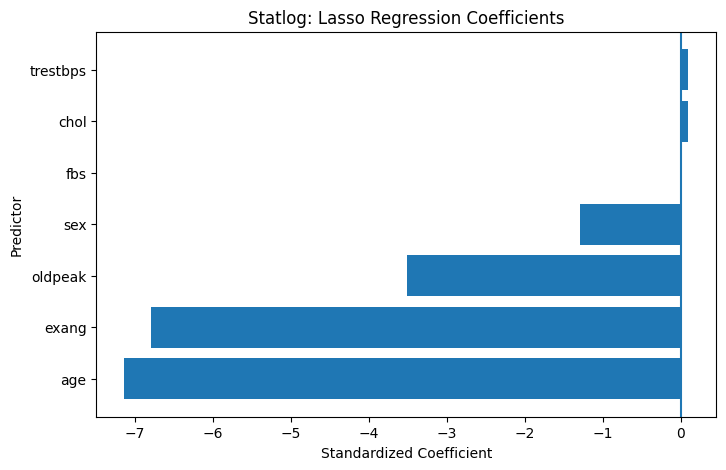

In [11]:
plot_coefficients(
    heart_lasso_coefficients,
    "Statlog: Lasso Regression Coefficients"
)

### Statlog Lasso Coefficient Interpretation

At the cross-validated Lasso alpha of 1.0, fasting blood sugar (`fbs`) was reduced completely to a
coefficient of zero. This means that Lasso did not find `fbs` useful enough to retain for predicting
maximum heart rate after accounting for the other predictors.

Age and exercise-induced angina (`exang`) had the largest negative standardized coefficients,
approximately -7.13 and -6.79 respectively. ST depression (`oldpeak`) also had a notable negative
coefficient of approximately -3.51.

Sex had a smaller negative coefficient, while resting blood pressure and cholesterol had coefficients
very close to zero.

Because the predictors were standardized before fitting the model, their coefficient magnitudes are
more directly comparable. In this model, age, exercise-induced angina, and ST depression contributed
substantially more information than fasting blood sugar, cholesterol, or resting blood pressure.

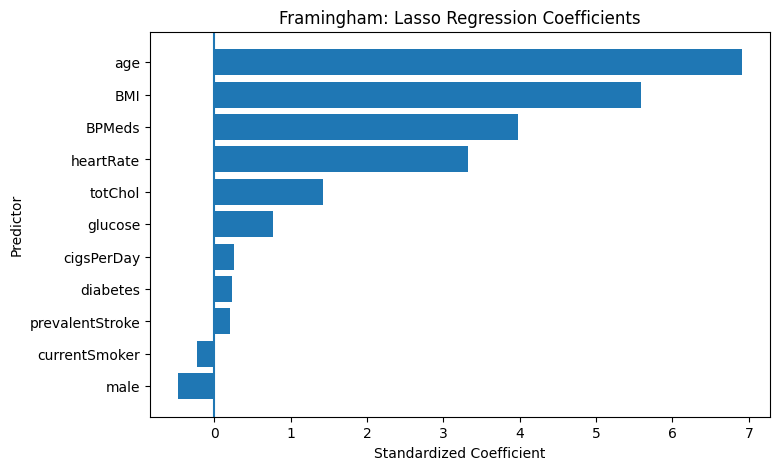

In [12]:
plot_coefficients(
    framingham_lasso_coefficients,
    "Framingham: Lasso Regression Coefficients"
)

### Framingham Lasso Coefficient Interpretation

At the selected Lasso alpha of 0.1, none of the eleven Framingham predictors were reduced completely
to zero.

Age had the largest standardized coefficient at approximately 6.91, followed by BMI at 5.59.
Blood-pressure medication use (`BPMeds`) and heart rate also had relatively large positive
coefficients.

Total cholesterol and glucose contributed more modestly, while variables including smoking status,
diabetes, prevalent stroke, and sex had comparatively small coefficients.

Unlike the Statlog model, Lasso did not perform meaningful feature elimination at the selected
regularization strength. This suggests that information relevant to systolic blood pressure is
distributed across several predictors rather than being concentrated in only a small subset.

## Effect of Regularization Strength

To examine the effect of the regularization parameter, Lasso models will be fitted across several
alpha values.

As alpha increases, the regularization penalty becomes stronger. This should cause coefficients to
shrink and may eventually force some coefficients to zero.

In [13]:
def lasso_alpha_analysis(df, predictors, target):

    data = df[predictors + [target]].dropna()

    X = data[predictors]
    y = data[target]

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    alphas = [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]

    results = []

    for alpha in alphas:

        model = Lasso(
            alpha=alpha,
            max_iter=50000
        )

        model.fit(
            X_scaled,
            y
        )

        predictions = model.predict(
            X_scaled
        )

        nonzero = np.sum(
            model.coef_ != 0
        )

        results.append({
            "Alpha": alpha,
            "R²": r2_score(y, predictions),
            "Nonzero Coefficients": nonzero
        })

    return pd.DataFrame(results).round(3)

In [14]:
heart_alpha_results = lasso_alpha_analysis(
    heart,
    heart_predictors,
    "thalach"
)

display(heart_alpha_results)

,Alpha,R²,Nonzero Coefficients
0,0.001,0.340,7
1,0.010,0.340,7
2,0.100,0.340,7
3,1.000,0.328,6
4,10.000,0.000,0
5,100.000,0.000,0


In [15]:
framingham_alpha_results = lasso_alpha_analysis(
    framingham,
    framingham_predictors,
    "sysBP"
)

display(framingham_alpha_results)

,Alpha,R²,Nonzero Coefficients
0,0.001,0.300,11
1,0.010,0.300,11
2,0.100,0.299,11
3,1.000,0.290,6
4,10.000,0.000,0
5,100.000,0.000,0


## Effect of Alpha on Lasso Regularization

The alpha experiments demonstrate the tradeoff created by increasing regularization strength.

### Statlog

At alpha values of 0.001, 0.01, and 0.1, all seven predictors remained in the model and the in-sample
R² remained approximately 0.340.

At alpha = 1.0, one predictor was eliminated and R² decreased slightly to 0.328.

At alpha values of 10 and 100, all coefficients were forced to zero and R² fell to 0.000. At these
levels, the regularization penalty was so strong that the model discarded all predictive information.

### Framingham

At alpha values of 0.001 and 0.01, all eleven predictors remained and R² was approximately 0.300.
At alpha = 0.1, all eleven still remained with almost identical performance.

At alpha = 1.0, Lasso retained only six predictors and R² fell to 0.290.

At alpha values of 10 and 100, all predictors were eliminated and R² fell to zero.

These results show why the regularization parameter must be tuned rather than selected arbitrarily.
Weak regularization changes the models very little, while excessively strong regularization can
remove useful predictors and cause severe underfitting.

need to note:
The R² values in these alpha tables were calculated on the same full dataset used to fit each model. So use those tables primarily to demonstrate how coefficients shrink as alpha increases, not as proof of which alpha generalizes best.

## Expected and Unexpected Findings

Some findings were consistent with expectations. Increasing the Lasso regularization strength
eventually reduced the number of retained predictors in both datasets, demonstrating the feature
selection behavior of Lasso.

However, the relatively small performance differences between ordinary linear regression, Lasso,
Ridge, and Elastic Net were somewhat unexpected. Regularization did not dramatically improve
prediction in either dataset.

It was also notable that Statlog Lasso eliminated fasting blood sugar at its selected alpha, while
Framingham Lasso retained all eleven predictors at its selected alpha. This indicates that the effect
of regularization depends strongly on the structure of the individual dataset.

## Relationship to Previous Exploratory Data Analysis

The exploratory analysis performed in Module B helped guide the Week 2 modeling choices.

Previous analysis of the Statlog dataset showed relationships involving age, maximum heart rate,
exercise-related variables, and ST depression. The Lasso results are broadly consistent with this
earlier work because age, exercise-induced angina, and ST depression received the largest
standardized coefficients.

Previous Framingham analysis identified age, blood pressure, BMI, cholesterol, smoking, and related
clinical factors as potentially relevant cardiovascular variables. Week 2 regularization suggests that
systolic blood pressure cannot be explained by only one or two of these predictors, as the selected
Lasso model retained all eleven features.

## Metrics and Hyperparameters Used

The primary metrics used in this analysis were:

- **R²:** Measures the proportion of variation in the outcome explained by the model. Higher values
  indicate greater explanatory performance.
- **RMSE:** Measures the typical magnitude of prediction error in the units of the outcome. Lower
  values indicate better predictive performance.
- **5-Fold Cross-Validation RMSE:** Evaluates performance across several different training-validation
  splits and provides a more reliable estimate of generalization than a single split.

The main hyperparameter was **alpha**, corresponding to the strength of the regularization penalty.
Larger alpha values produce stronger coefficient shrinkage.

Elastic Net also used **l1_ratio**. Values closer to 1 make Elastic Net behave more like Lasso, while
values closer to 0 make it behave more like Ridge.

GridSearchCV was used with five-fold cross-validation to select hyperparameters based on the lowest
cross-validation RMSE.

# Week 2 Overall Conclusion

Week 2 compared ordinary linear regression with Lasso, Ridge, and Elastic Net regularization across
the Statlog Heart Disease and Framingham Heart Study datasets.

For Statlog, ordinary linear regression achieved the strongest held-out test performance with a testing
R² of 0.198 and RMSE of 21.616. Ridge and Elastic Net performed almost identically, while Lasso
performed somewhat worse on the held-out test set. Cross-validation performance was very similar
across all four approaches, suggesting that regularization offered little overall predictive advantage.

Lasso nevertheless provided useful feature-selection information in Statlog. At the selected alpha of
1.0, fasting blood sugar was eliminated completely, while age, exercise-induced angina, and ST
depression received the largest standardized coefficients.

For Framingham, regularization produced only marginal improvements. Ridge achieved the lowest testing
RMSE of 18.668 compared with 18.685 for ordinary linear regression, while all three regularized
models achieved a testing R² of approximately 0.260. These differences were very small, indicating
that regularization improved model stability only modestly.

The alpha experiments demonstrated that stronger regularization progressively reduces model complexity.
At moderate alpha values, Lasso began eliminating predictors, while alpha values of 10 or greater
removed every predictor in both datasets and reduced R² to zero. This illustrates underfitting caused
by excessive regularization.

Overall, Ridge was marginally preferable for the Framingham analysis, while ordinary linear regression
remained competitive for Statlog. Lasso was particularly useful as an exploratory feature-selection
tool even when it did not provide the strongest predictive performance. The results demonstrate that
regularization strength should be selected using cross-validation rather than assuming that stronger
regularization will necessarily improve a model.

## AI Use Disclosure

ChatGPT was used as an assistive tool to help organize and articulate formal written interpretations after the analysis had been performed and the models had been run, and basic info was identified by me first.